In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [76]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle (3).json


{'kaggle (3).json': b'{"username":"darrangmanas","key":"a87354b795892aba87911b66d441a003"}'}

In [77]:
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle
!chmod 600 ~/.kaggle/kaggle.json

mkdir: cannot create directory ‘/root/.kaggle’: File exists


In [78]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("johnsmith88/heart-disease-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'heart-disease-dataset' dataset.
Path to dataset files: /kaggle/input/heart-disease-dataset


In [79]:
!kaggle datasets download -d johnsmith88/heart-disease-dataset

Dataset URL: https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset
License(s): unknown
heart-disease-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [80]:
pd.set_option('display.max_columns', None)          # Show all columns
pd.set_option('display.width', None)                # Adjust width dynamically
pd.set_option('display.expand_frame_repr', False)   # Prevent column wrapping

| Feature    | Description                                                                                     |
| ---------- | ----------------------------------------------------------------------------------------------- |
| `age`      | Age of the patient (years).                                                                     |
| `sex`      | Patient sex (1 = male, 0 = female).                                                             |
| `cp`       | Chest pain type (categorical: typical angina, atypical angina, non-anginal pain, asymptomatic). |
| `trestbps` | Resting blood pressure (in mm Hg).                                                              |
| `chol`     | Serum cholesterol level (mg/dl).                                                                |
| `fbs`      | Fasting blood sugar > 120 mg/dl (1 = true; 0 = false).                                          |
| `restecg`  | Resting ECG results (categorical ECG categories).                                               |
| `thalach`  | Maximum heart rate achieved during exercise.                                                    |
| `exang`    | Exercise-induced angina (1 = yes; 0 = no).                                                      |
| `oldpeak`  | ST depression induced by exercise relative to rest.                                             |
| `slope`    | Slope of the peak exercise ST segment (categorical).                                            |
| `ca`       | Number of major vessels (0–3) colored by fluoroscopy.                                           |
| `thal`     | Result of thalassemia test (categorical: e.g., normal/fixed/reversible).                        |
| `target`   | Heart disease label (1 = disease; 0 = no disease).                                              |


In [81]:
df=pd.read_csv("/kaggle/input/heart-disease-dataset/heart.csv")

# DATA EXPLORATION

In [82]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [84]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [85]:
duplicates = df.duplicated().sum()
if duplicates > 0:
    df = df.drop_duplicates()

In [86]:
df.duplicated().sum()

np.int64(0)

In [87]:
missing_values = df.isnull().sum()

In [88]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [89]:
print("--- DUPLICATE ROWS ---")
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")
if duplicates > 0:
  print("Example of duplicated data:")
  print(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)).head())
print("\n")

--- DUPLICATE ROWS ---
Number of duplicate rows: 0




In [90]:
df = df.rename(columns={
    "age" : "Age",
    "sex" : "Sex",
    "cp": "Chest Pain Type",
    "trestbps": "Resting BP",
    "chol": "Cholesterol",
    "fbs": "Fasting Blood Sugar",
    "restecg": "Resting ECG",
    "thalach": "Max Heart Rate",
    "exang": "Exercise Induced Angina",
    "oldpeak": "ST Depression",
    "slope": "ST Slope",
    "ca": "Num Major Vessels",
    "thal": "Thalassemia Test Results",
    "target": "Heart Disease"
})

In [91]:
df.columns

Index(['Age', 'Sex', 'Chest Pain Type', 'Resting BP', 'Cholesterol',
       'Fasting Blood Sugar', 'Resting ECG', 'Max Heart Rate',
       'Exercise Induced Angina', 'ST Depression', 'ST Slope',
       'Num Major Vessels', 'Thalassemia Test Results', 'Heart Disease'],
      dtype='object')

In [92]:
df['Heart Disease'].value_counts()

,count
Heart Disease,
1,164
0,138


In [93]:
for col in df.columns:
    print(f"{col} unique values: {df[col].nunique()}")

Age unique values: 41
Sex unique values: 2
Chest Pain Type unique values: 4
Resting BP unique values: 49
Cholesterol unique values: 152
Fasting Blood Sugar unique values: 2
Resting ECG unique values: 3
Max Heart Rate unique values: 91
Exercise Induced Angina unique values: 2
ST Depression unique values: 40
ST Slope unique values: 3
Num Major Vessels unique values: 5
Thalassemia Test Results unique values: 4
Heart Disease unique values: 2


In [94]:
for col in df.select_dtypes(include=np.number).columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col} has outliers: {outliers.shape[0]} rows")

Age has outliers: 0 rows
Sex has outliers: 0 rows
Chest Pain Type has outliers: 0 rows
Resting BP has outliers: 9 rows
Cholesterol has outliers: 5 rows
Fasting Blood Sugar has outliers: 45 rows
Resting ECG has outliers: 0 rows
Max Heart Rate has outliers: 1 rows
Exercise Induced Angina has outliers: 0 rows
ST Depression has outliers: 5 rows
ST Slope has outliers: 0 rows
Num Major Vessels has outliers: 24 rows
Thalassemia Test Results has outliers: 2 rows
Heart Disease has outliers: 0 rows


# ANALYSIS AND VISUALIZATION

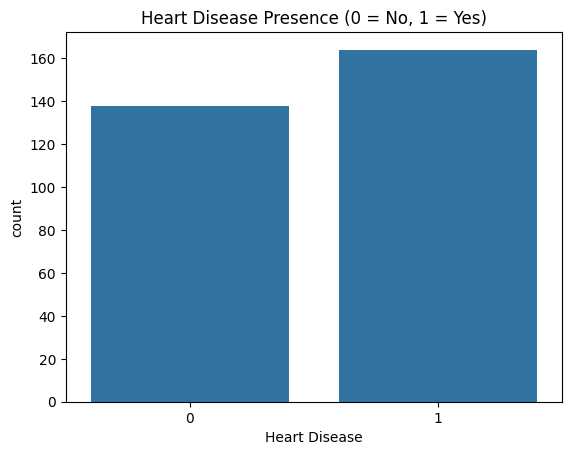

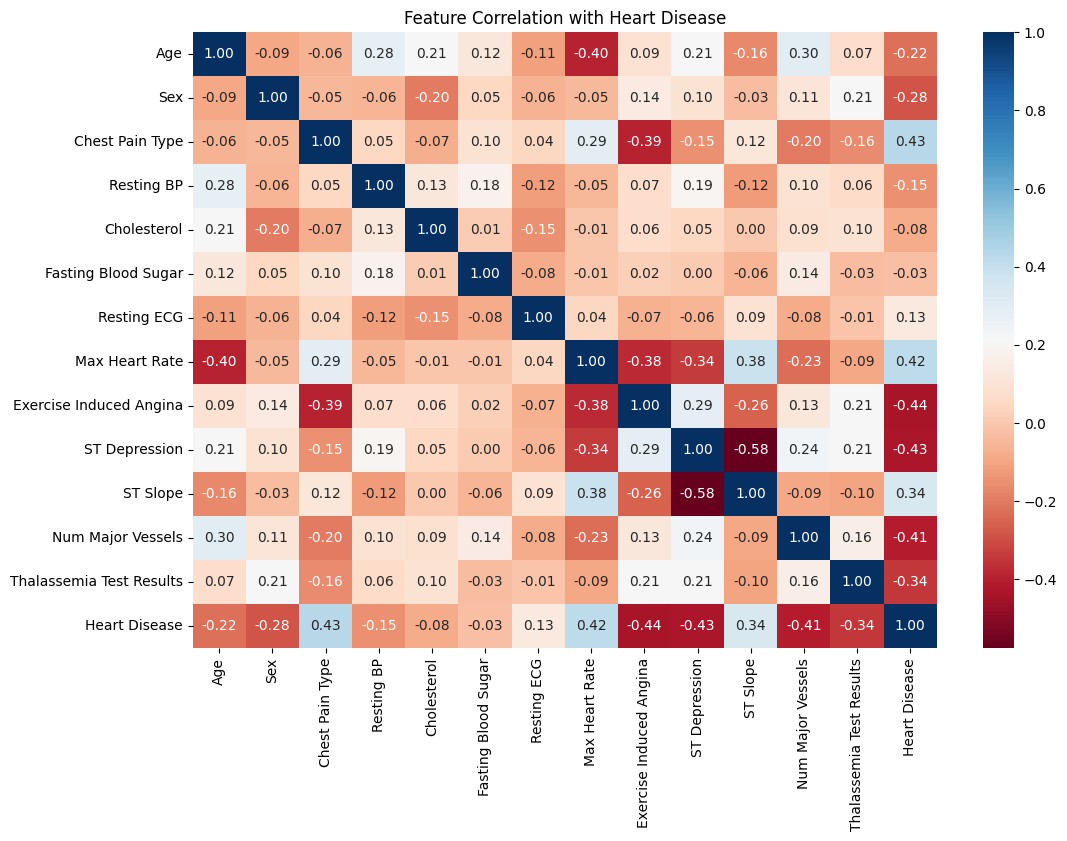

In [95]:
# Target Distribution
sns.countplot(x='Heart Disease', data=df)
plt.title('Heart Disease Presence (0 = No, 1 = Yes)')
plt.show()

# Correlation Matrix
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='RdBu', fmt='.2f')
plt.title('Feature Correlation with Heart Disease')
plt.show()

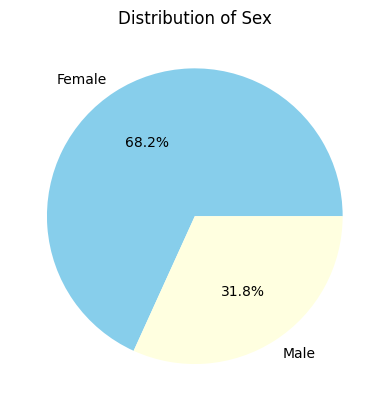

In [96]:
plt.pie(df['Sex'].value_counts(), labels=['Female', 'Male'], autopct='%1.1f%%', colors=['skyblue', 'lightyellow'])
plt.title('Distribution of Sex')
plt.show()

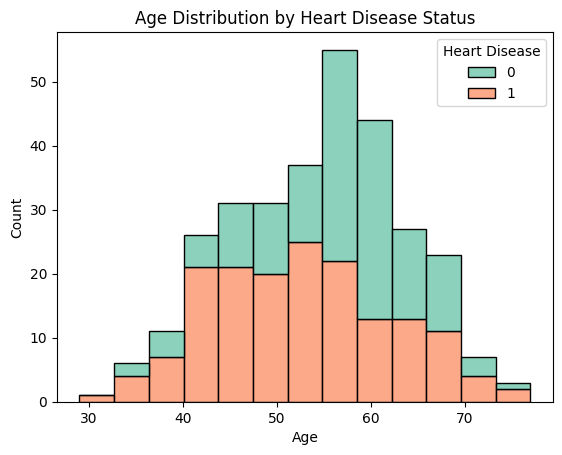

In [97]:
sns.histplot(data=df, x='Age', hue='Heart Disease', multiple='stack', palette='Set2')
plt.title('Age Distribution by Heart Disease Status')
plt.show()

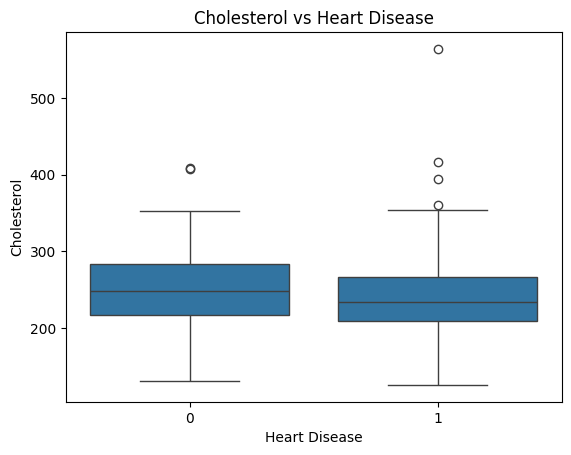

In [98]:
sns.boxplot(x="Heart Disease", y="Cholesterol", data=df)
plt.title("Cholesterol vs Heart Disease")
plt.show()

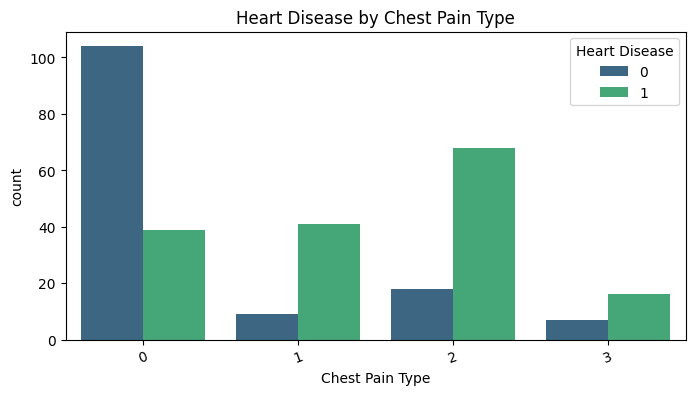

In [99]:
plt.figure(figsize=(8,4))
# Changed df_copy to df and added the palette parameter
sns.countplot(data=df, x='Chest Pain Type', hue='Heart Disease', palette='viridis')
plt.xticks(rotation=20)
plt.title('Heart Disease by Chest Pain Type')
plt.show()

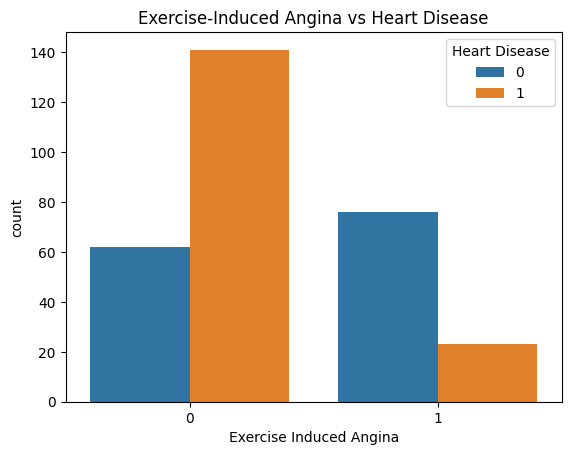

In [100]:
sns.countplot(x="Exercise Induced Angina", hue="Heart Disease", data=df)
plt.title("Exercise-Induced Angina vs Heart Disease")
plt.show()

<Figure size 1200x800 with 0 Axes>

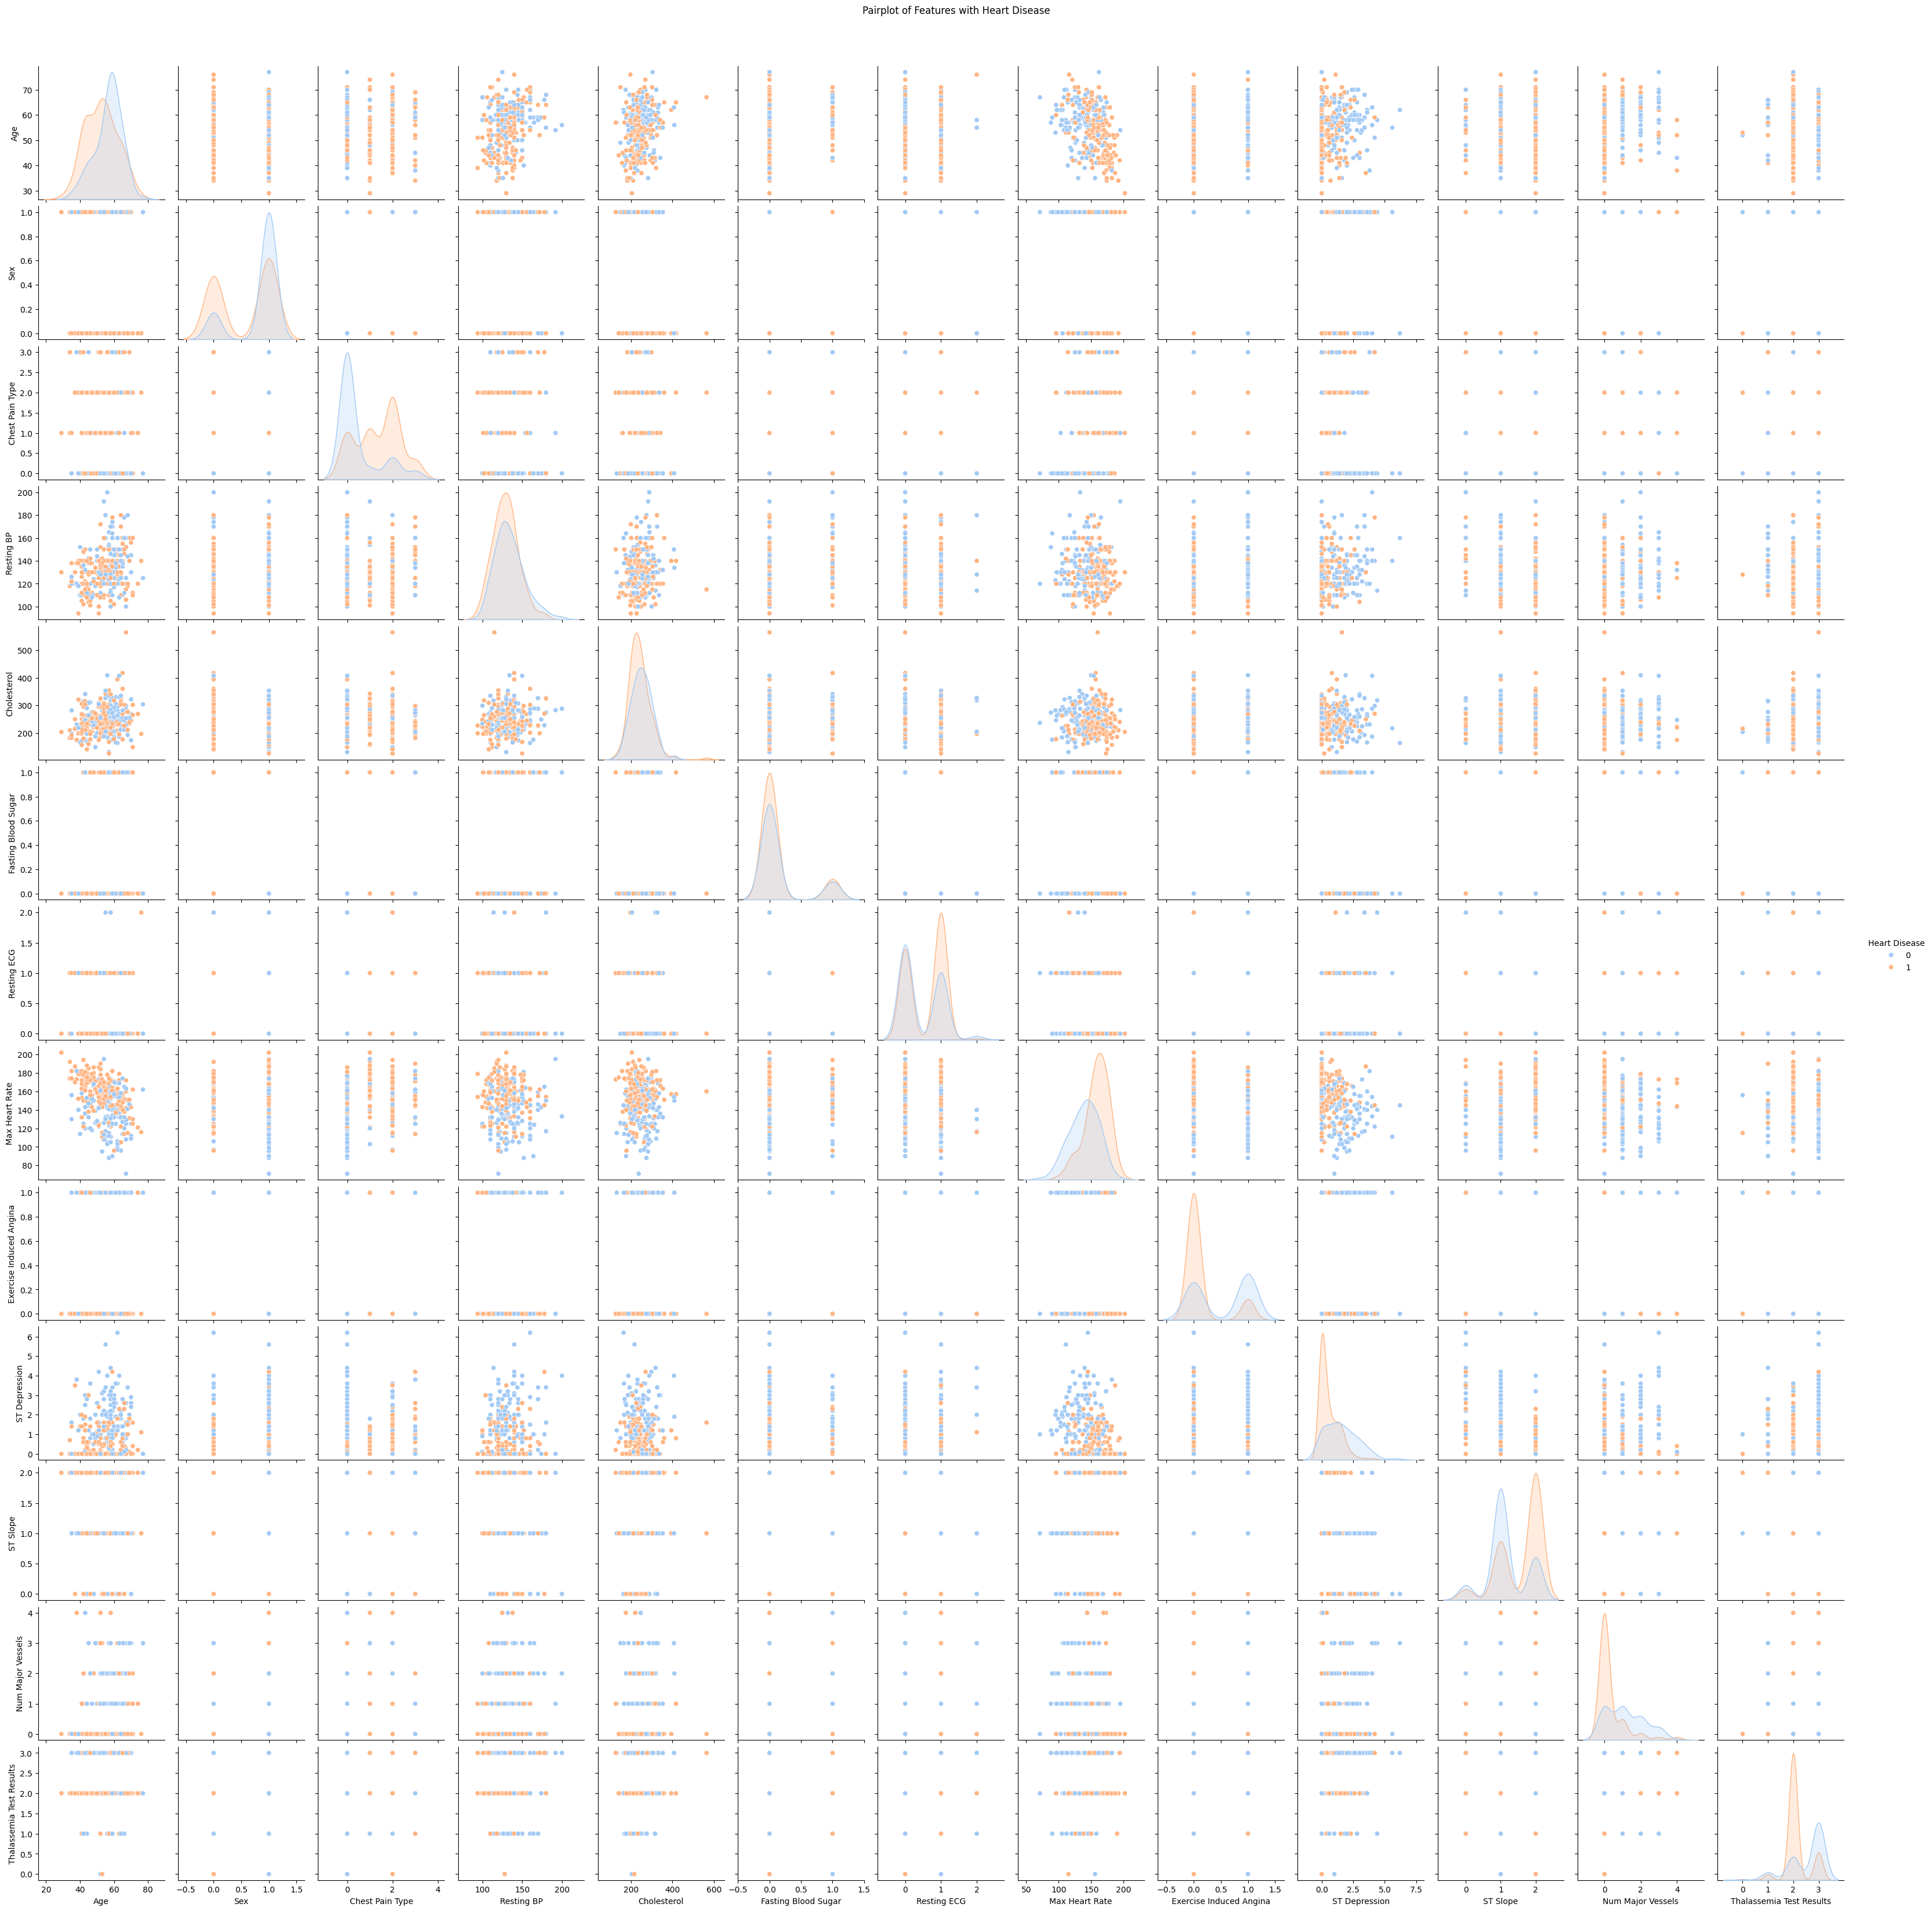

In [101]:
plt.figure(figsize=(12,8))
sns.pairplot(df, hue='Heart Disease', palette='pastel',height=2.5)
plt.suptitle('Pairplot of Features with Heart Disease', y=1.02)
plt.show()

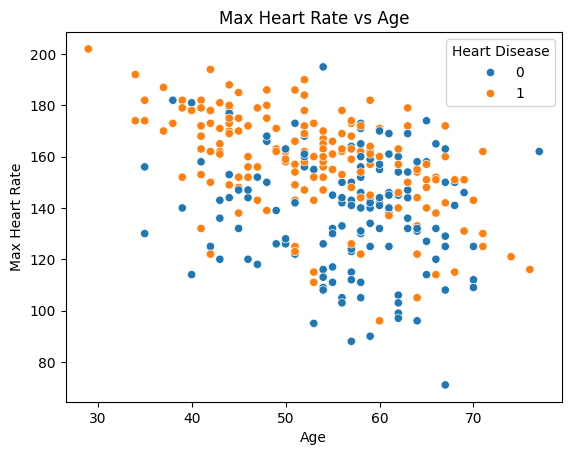

In [102]:
sns.scatterplot(
    x="Age",
    y="Max Heart Rate",
    hue="Heart Disease",
    data=df
)
plt.title("Max Heart Rate vs Age")
plt.show()

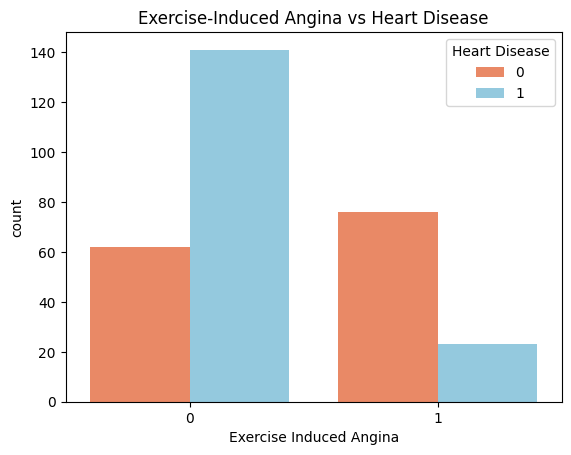

In [103]:
sns.countplot(
    x="Exercise Induced Angina",
    hue="Heart Disease",
    palette=["coral", "skyblue"],
    data=df
)
plt.title("Exercise-Induced Angina vs Heart Disease")
plt.show()

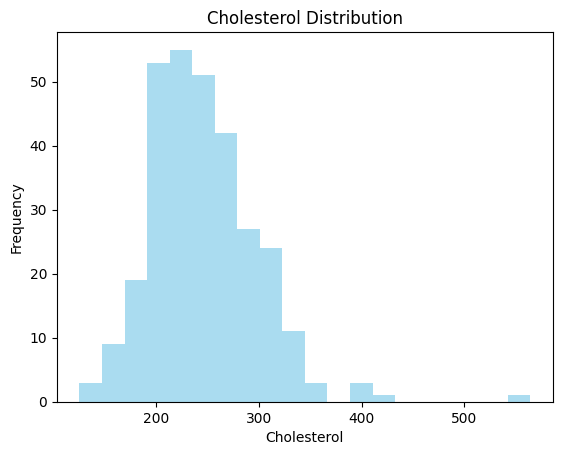

In [104]:
df['Cholesterol'].plot(
    kind='hist',
    bins=20,
    color='skyblue',
    alpha=0.7
)

plt.title('Cholesterol Distribution')
plt.xlabel('Cholesterol')
plt.ylabel('Frequency')
plt.show()

In [105]:
df.columns

Index(['Age', 'Sex', 'Chest Pain Type', 'Resting BP', 'Cholesterol',
       'Fasting Blood Sugar', 'Resting ECG', 'Max Heart Rate',
       'Exercise Induced Angina', 'ST Depression', 'ST Slope',
       'Num Major Vessels', 'Thalassemia Test Results', 'Heart Disease'],
      dtype='object')

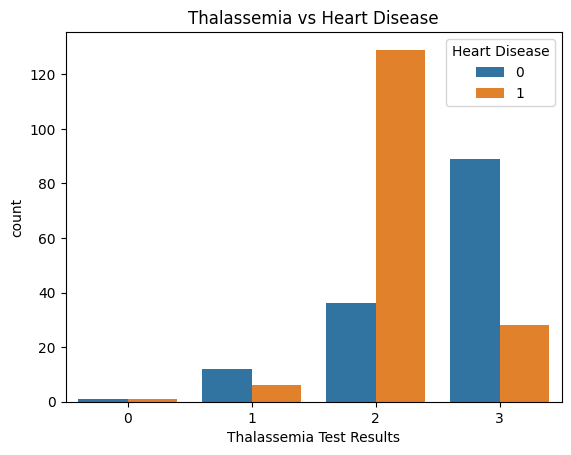

In [106]:
sns.countplot(x="Thalassemia Test Results", hue="Heart Disease", data=df)
plt.title("Thalassemia vs Heart Disease")
plt.show()

# ML Preparation

In [107]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [108]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features (X) and target (y)
X = df.drop('Heart Disease', axis=1)
y = df['Heart Disease']

# Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [109]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Initialize and train the model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

# Predict on test data
predictions = model.predict(X_test_scaled)

In [110]:
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(max_depth=5
                                            ,class_weight='balanced',
                                            random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        max_depth=6,
        random_state=42
    ), "KNeighborsClassifier": KNeighborsClassifier(n_neighbors=5),
    "XGBClassifier": XGBClassifier(random_state=42,
                                   eval_metric='logloss')
}

In [111]:
scaled_models = ["Logistic Regression", "KNeighborsClassifier"]
model_accuracies = {}
for name, model in models.items():

    if name in scaled_models:
        model.fit(X_train_scaled, y_train)
        train_acc = model.score(X_train_scaled, y_train)
        test_acc = model.score(X_test_scaled, y_test)
    else:
        model.fit(X_train, y_train)
        train_acc = model.score(X_train, y_train)
        test_acc = model.score(X_test, y_test)
        print(f"{name}")

    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Test Accuracy: {test_acc:.4f}")
    print("-----------------------")
    model_accuracies[name] = [test_acc, train_acc]

Train Accuracy: 0.8589
Test Accuracy: 0.8033
-----------------------
Decision Tree
Train Accuracy: 0.9419
Test Accuracy: 0.7705
-----------------------
Random Forest
Train Accuracy: 0.9917
Test Accuracy: 0.7705
-----------------------
Train Accuracy: 0.8963
Test Accuracy: 0.7869
-----------------------
XGBClassifier
Train Accuracy: 1.0000
Test Accuracy: 0.7213
-----------------------


In [112]:
model_accuracies = pd.DataFrame(model_accuracies, index=['Test Accuracy', 'Train Accuracy']).T
model_accuracies.sort_values(by='Test Accuracy', ascending=False, inplace=True)

In [113]:
model_accuracies.sort_values(by='Test Accuracy', ascending=False, inplace=True)
model_accuracies

,Test Accuracy,Train Accuracy
Logistic Regression,0.803279,0.858921
KNeighborsClassifier,0.786885,0.896266
Decision Tree,0.770492,0.941909
Random Forest,0.770492,0.991701
XGBClassifier,0.721311,1.000000


--- Logistic Regression ---
Train Accuracy: 0.8589
Test Accuracy:  0.8033


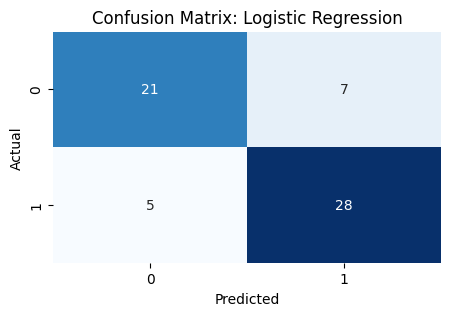

--- Decision Tree ---
Train Accuracy: 0.9419
Test Accuracy:  0.7705


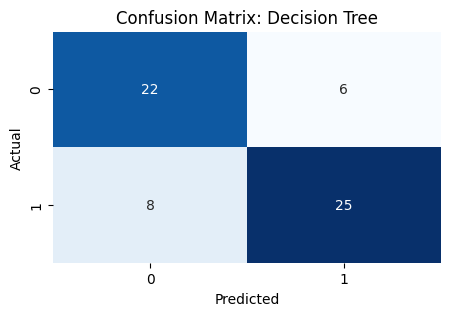

--- Random Forest ---
Train Accuracy: 0.9917
Test Accuracy:  0.7705


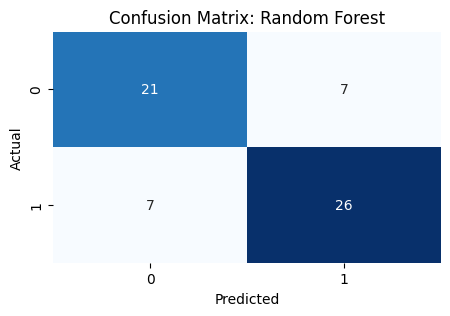

--- KNeighborsClassifier ---
Train Accuracy: 0.8963
Test Accuracy:  0.7869


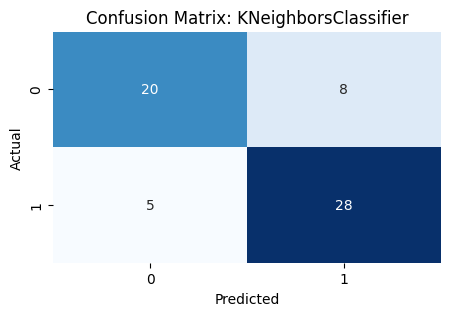

--- XGBClassifier ---
Train Accuracy: 1.0000
Test Accuracy:  0.7213


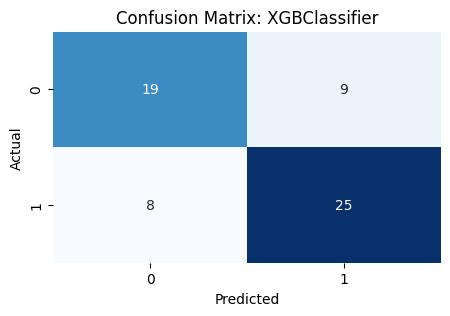

In [114]:
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

model_performance = {}

for name, model in models.items():

    if name in scaled_models:
        model.fit(X_train_scaled, y_train)
        y_train_pred = model.predict(X_train_scaled)
        y_test_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)

    model_performance[name] = {'Train': train_acc, 'Test': test_acc}

    print(f"--- {name} ---")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Test Accuracy:  {test_acc:.4f}")
    cm = confusion_matrix(y_test, y_test_pred)
    plt.figure(figsize=(5, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [115]:
import joblib

# 1. First, SAVE your trained model (this creates the actual file)
joblib.dump(model, 'heart_disease_rf_model.pkl')

# 2. Now you can LOAD that exact file you just created
loaded_model = joblib.load('heart_disease_rf_model.pkl')

print("Model successfully saved and loaded!")

Model successfully saved and loaded!
